# Hand Gesture Recognition Using Deep Learning

## Computer Vision
Berdimbet Alima

**Assignment 1**



### Project Objective

The objective of this project is to develop a computer vision model capable of recognizing three different hand gestures: **Peace Sign, Thumbs Up, and Stop**.

A self-collected image dataset is used for this project. The complete workflow includes dataset exploration, image preprocessing, data augmentation, model training, evaluation, and comparison.

Two approaches will be investigated:

1. A baseline **Convolutional Neural Network (CNN)**.
2. An improved model using **Transfer Learning**.

The models will be evaluated using accuracy, precision, recall, F1-score, and a confusion matrix.

## 1. Import Libraries

The required Python libraries are imported for image processing, visualization, model development, and evaluation.

In [93]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## 2. Reproducibility

A fixed random seed is used to make the experimental results more reproducible.

In [94]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed:", SEED)

Random seed: 42


It helps produce consistent results when the code is executed multiple times.

## 3. Connect Google Drive

Google Drive is mounted to access the self-collected hand gesture dataset.

In [95]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 4. Dataset Loading

The dataset contains three classes of hand gestures:

- **Peace**
- **Thumbs Up**
- **Stop**

All images were collected specifically for this computer vision project.

In [96]:
DATASET_PATH = "/content/drive/MyDrive/Computer_Vision_Assignment/hand_gesture_dataset"

print("Dataset path:", DATASET_PATH)
print("Dataset exists:", os.path.exists(DATASET_PATH))

Dataset path: /content/drive/MyDrive/Computer_Vision_Assignment/hand_gesture_dataset
Dataset exists: True


## 5. Dataset Exploration

Before training the models, the dataset is explored to verify the class structure and the number of images available in each category.

In [97]:
class_names = sorted([
    folder for folder in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, folder))
])

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Classes: ['peace', 'stop', 'thumbs_up']
Number of classes: 3


In [98]:
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

class_counts = {}

for class_name in class_names:
    class_path = os.path.join(DATASET_PATH, class_name)

    images = [
        file for file in os.listdir(class_path)
        if file.lower().endswith(image_extensions)
    ]

    class_counts[class_name] = len(images)

for class_name, count in class_counts.items():
    print(f"{class_name}: {count} images")

print("\nTotal original images:", sum(class_counts.values()))

peace: 127 images
stop: 121 images
thumbs_up: 124 images

Total original images: 372


### 5.1 Dataset Distribution

The following table summarizes the number of original images collected for each hand gesture class.

In [99]:
dataset_summary = pd.DataFrame({
    "Class": list(class_counts.keys()),
    "Number of Images": list(class_counts.values())
})

dataset_summary.loc[len(dataset_summary)] = [
    "Total",
    dataset_summary["Number of Images"].sum()
]

dataset_summary

,Class,Number of Images
0,peace,127
1,stop,121
2,thumbs_up,124
3,Total,372


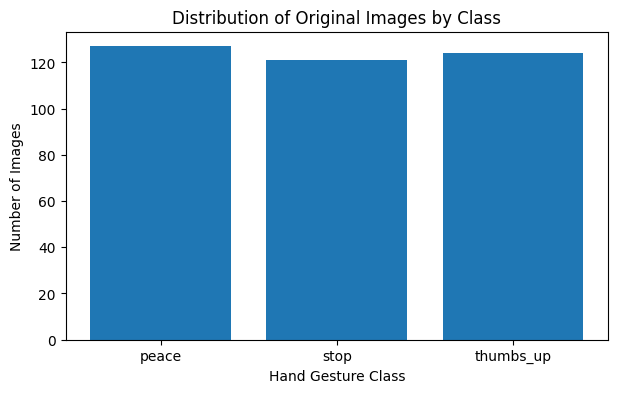

In [100]:
plot_counts = pd.Series(class_counts)

plt.figure(figsize=(7, 4))
plt.bar(plot_counts.index, plot_counts.values)

plt.title("Distribution of Original Images by Class")
plt.xlabel("Hand Gesture Class")
plt.ylabel("Number of Images")

plt.show()

### 5.2 Sample Images

Several randomly selected images from each class are displayed below to visually inspect the self-collected dataset.

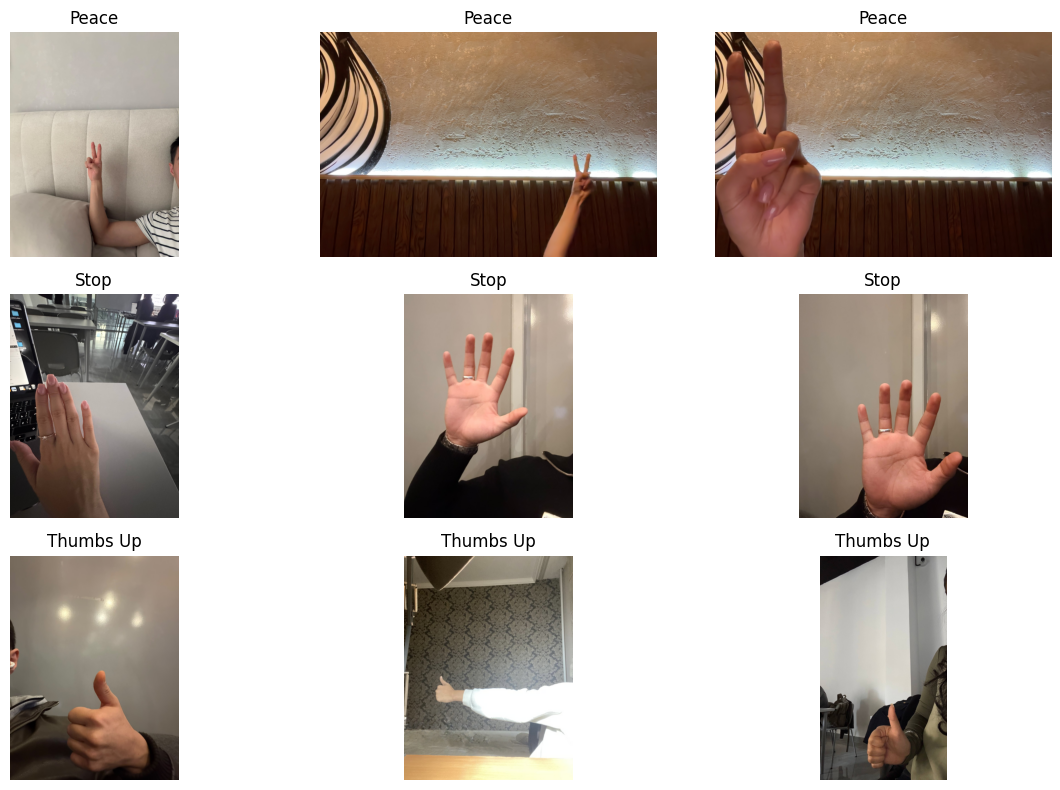

In [101]:
from PIL import Image

plt.figure(figsize=(12, 8))

image_number = 1

for class_name in class_names:

    class_path = os.path.join(DATASET_PATH, class_name)

    image_files = [
        file for file in os.listdir(class_path)
        if file.lower().endswith(image_extensions)
    ]

    selected_images = random.sample(
        image_files,
        min(3, len(image_files))
    )

    for image_file in selected_images:

        image_path = os.path.join(class_path, image_file)
        image = Image.open(image_path)

        plt.subplot(len(class_names), 3, image_number)
        plt.imshow(image)
        plt.title(class_name.replace("_", " ").title())
        plt.axis("off")

        image_number += 1

plt.tight_layout()
plt.show()

## 6. Data Preprocessing

Before model training, all images are resized to a consistent size of **224 × 224 pixels**.

The dataset is divided into training, validation, and test sets. This separation allows the model to learn from the training data while the validation and test sets are used to evaluate its performance on unseen images.

The following split is used:

- **70% Training**
- **15% Validation**
- **15% Testing**

In [102]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: (224, 224)
Batch size: 16


In [103]:
from sklearn.model_selection import train_test_split

file_paths = []
labels = []

for class_name in class_names:
    class_path = os.path.join(DATASET_PATH, class_name)

    for file_name in os.listdir(class_path):
        if file_name.lower().endswith(image_extensions):
            file_paths.append(
                os.path.join(class_path, file_name)
            )
            labels.append(class_name)

data_df = pd.DataFrame({
    "filepath": file_paths,
    "label": labels
})

print("Total images:", len(data_df))

data_df.head()

Total images: 372


,filepath,label
0,/content/drive/MyDrive/Computer_Vision_Assignm...,peace
1,/content/drive/MyDrive/Computer_Vision_Assignm...,peace
2,/content/drive/MyDrive/Computer_Vision_Assignm...,peace
3,/content/drive/MyDrive/Computer_Vision_Assignm...,peace
4,/content/drive/MyDrive/Computer_Vision_Assignm...,peace


In [104]:
train_val_df, test_df = train_test_split(
    data_df,
    test_size=0.15,
    stratify=data_df["label"],
    random_state=SEED
)

print("Train + Validation:", len(train_val_df))
print("Test:", len(test_df))

Train + Validation: 316
Test: 56


In [105]:
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.1765,
    stratify=train_val_df["label"],
    random_state=SEED
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nTotal:", len(train_df) + len(val_df) + len(test_df))

Training images: 260
Validation images: 56
Test images: 56

Total: 372


### 6.1 Dataset Split

The dataset was divided using stratified sampling to preserve approximately the same class distribution in each subset.

The training set is used for model learning, the validation set is used to monitor performance during training, and the test set is reserved for final evaluation.

In [106]:
split_summary = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Test": test_df["label"].value_counts()
}).fillna(0).astype(int)

split_summary

,Training,Validation,Test
label,,,
peace,89,19,19
stop,85,18,18
thumbs_up,86,19,19


### 6.2 Image Loading and Resizing

TensorFlow datasets are created from the image file paths. Each image is automatically resized to 224 × 224 pixels and grouped into batches for efficient model training.

In [107]:
label_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

print(label_to_index)

{'peace': 0, 'stop': 1, 'thumbs_up': 2}


In [108]:
def load_image(filepath, label):

    image = tf.io.read_file(filepath)
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(image, tf.float32)

    return image, label

All images must have the same dimensions before they can be processed by the neural network.

In [109]:
def create_dataset(df, training=False):

    paths = df["filepath"].values

    encoded_labels = (
        df["label"]
        .map(label_to_index)
        .values
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, encoded_labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=SEED
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset

In [110]:
train_ds = create_dataset(
    train_df,
    training=True
)

val_ds = create_dataset(
    val_df
)

test_ds = create_dataset(
    test_df
)

print("TensorFlow datasets created successfully.")

TensorFlow datasets created successfully.


In [111]:
for images, labels_batch in train_ds.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels_batch.shape)

    print("\nMinimum pixel value:",
          tf.reduce_min(images).numpy())

    print("Maximum pixel value:",
          tf.reduce_max(images).numpy())

Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)

Minimum pixel value: 0.0
Maximum pixel value: 255.0


## 7. Data Augmentation

Data augmentation is applied to the training images to artificially increase image diversity without collecting additional photographs.

Random transformations help the model become more robust to variations in hand position, orientation, size, and lighting.

The augmentation pipeline includes:

- Random horizontal flipping
- Random rotation
- Random zoom
- Random translation
- Random contrast adjustment

Augmentation is applied only to the training data. Validation and test images remain unchanged to provide an unbiased evaluation.

In [112]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(
        0.05,
        fill_mode="nearest"
    ),
    tf.keras.layers.RandomZoom(
        height_factor=(-0.05, 0.05),
        width_factor=(-0.05, 0.05),
        fill_mode="nearest"
    ),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode="nearest"
    ),
    tf.keras.layers.RandomContrast(0.10)
], name="data_augmentation")

print("Data augmentation pipeline created.")

Data augmentation pipeline created.


### 7.1 Visualization of Data Augmentation

The following examples demonstrate how a single original training image can be transformed into several different variations using the augmentation pipeline.

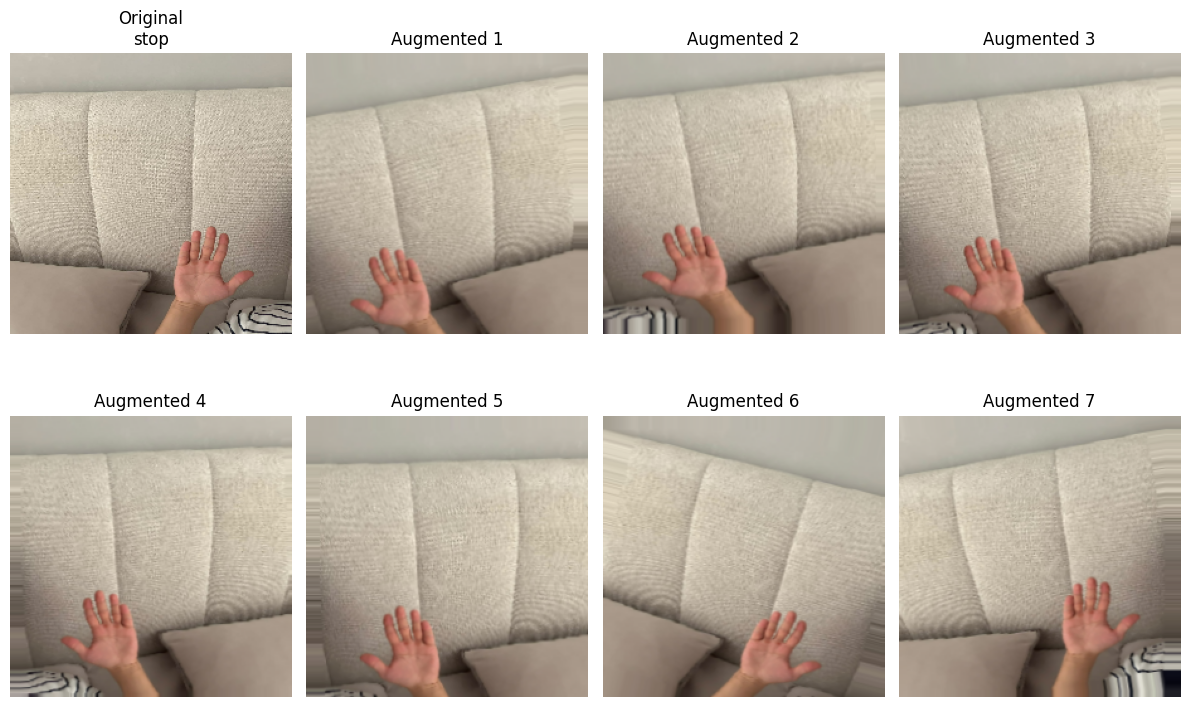

In [113]:
for images, labels_batch in train_ds.take(1):

    original_image = images[0]
    original_label = labels_batch[0]

    plt.figure(figsize=(12, 8))

    plt.subplot(2, 4, 1)
    plt.imshow(
        tf.cast(original_image, tf.uint8)
    )
    plt.title(
        "Original\n" +
        class_names[original_label.numpy()]
    )
    plt.axis("off")

    for i in range(1, 8):

        augmented_image = data_augmentation(
            tf.expand_dims(original_image, 0),
            training=True
        )[0]

        plt.subplot(2, 4, i + 1)

        plt.imshow(
            tf.cast(
                tf.clip_by_value(
                    augmented_image,
                    0,
                    255
                ),
                tf.uint8
            )
        )

        plt.title(f"Augmented {i}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

### 7.2 Preprocessing Summary

The original dataset contains **372 self-collected images** belonging to three hand gesture classes.

All images are resized to **224 × 224 pixels** before being passed to the neural network.

The dataset is divided into training, validation, and test subsets using stratified sampling. Data augmentation is applied dynamically only during training, meaning that augmented images are generated during model training rather than permanently stored as additional files.

This approach increases training diversity while keeping the validation and test sets unchanged for reliable model evaluation.

## 8. Baseline Model — Simple CNN

A simple Convolutional Neural Network (CNN) is used as the baseline model.

CNNs are well suited for image classification because convolutional layers automatically learn visual features such as edges, shapes, and patterns.

The baseline model consists of three convolutional blocks followed by fully connected layers for classification into the three hand gesture classes.

In [114]:
from tensorflow.keras import layers, models

baseline_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(len(class_names), activation="softmax")
])

baseline_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,347 (42.61 MB)

 Trainable params: 11,169,347 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

### 8.1 Model Compilation

The baseline CNN is compiled using the Adam optimizer and sparse categorical cross-entropy loss.

Since this is a multi-class classification problem with integer class labels, sparse categorical cross-entropy is appropriate. Accuracy is used as the primary training metric.

In [115]:
baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Baseline CNN compiled successfully.")

Baseline CNN compiled successfully.


### 8.2 Training Strategy

Early stopping is used to reduce the risk of overfitting. Training stops when the validation loss no longer improves for several consecutive epochs, and the best model weights are restored.

In [116]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

print("Early stopping configured.")

Early stopping configured.


### 8.3 Baseline Model Training

The baseline CNN is trained using the training dataset, while the validation dataset is used to monitor generalization performance after each epoch.

In [117]:
EPOCHS = 20

history_baseline = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

Epoch 1/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 48s 2s/step - accuracy: 0.3885 - loss: 1.2009 - val_accuracy: 0.3393 - val_loss: 1.1001
Epoch 2/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step - accuracy: 0.4115 - loss: 1.0782 - val_accuracy: 0.4107 - val_loss: 1.0092
Epoch 3/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 43s 2s/step - accuracy: 0.5000 - loss: 0.9976 - val_accuracy: 0.5357 - val_loss: 0.8933
Epoch 4/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 49s 3s/step - accuracy: 0.6000 - loss: 0.8539 - val_accuracy: 0.6429 - val_loss: 0.7700
Epoch 5/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 74s 2s/step - accuracy: 0.6077 - loss: 0.8107 - val_accuracy: 0.6250 - val_loss: 0.7691
Epoch 6/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 43s 2s/step - accuracy: 0.6462 - loss: 0.7930 - val_accuracy: 0.7143 - val_loss: 0.7091
Epoch 7/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - accuracy: 0.7192 - loss: 0.6779 - val_accuracy: 0.6607 - val_loss: 0.7146
Epoch 8/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - accuracy: 0.6808 - loss: 0.7649 - val_accuracy: 0.6429 - val_loss:

### 8.4 Training History

Training and validation accuracy and loss are visualized to analyze the learning behavior of the baseline CNN and identify possible overfitting.

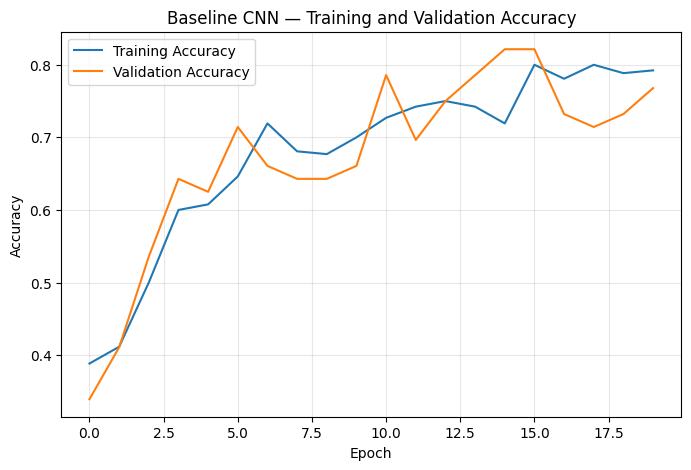

In [118]:
history_df = pd.DataFrame(history_baseline.history)

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_df["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Baseline CNN — Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

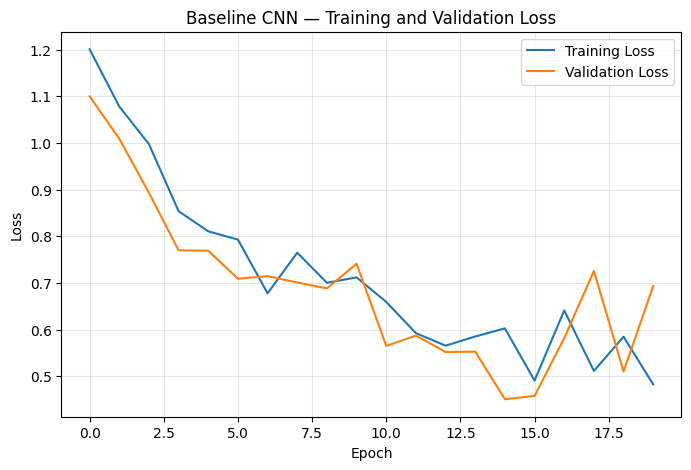

In [119]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["loss"],
    label="Training Loss"
)

plt.plot(
    history_df["val_loss"],
    label="Validation Loss"
)

plt.title("Baseline CNN — Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 9. Baseline Model Evaluation

The trained baseline CNN is evaluated on the independent test dataset. The test data was not used during model training or validation.

In [120]:
baseline_test_loss, baseline_test_accuracy = baseline_model.evaluate(
    test_ds
)

print(f"Baseline Test Loss: {baseline_test_loss:.4f}")
print(f"Baseline Test Accuracy: {baseline_test_accuracy:.4f}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 507ms/step - accuracy: 0.8393 - loss: 0.4877
Baseline Test Loss: 0.4877
Baseline Test Accuracy: 0.8393


In [121]:
y_true = []
y_pred_baseline = []

for images, labels_batch in test_ds:

    predictions = baseline_model.predict(
        images,
        verbose=0
    )

    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(
        labels_batch.numpy()
    )

    y_pred_baseline.extend(
        predicted_classes
    )

y_true = np.array(y_true)
y_pred_baseline = np.array(y_pred_baseline)

print("Predictions generated:", len(y_pred_baseline))

Predictions generated: 56


### 9.1 Classification Metrics

Accuracy, precision, recall, and F1-score are calculated to provide a comprehensive evaluation of the baseline model.

Macro averaging gives equal importance to each hand gesture class.

In [122]:
baseline_accuracy = accuracy_score(
    y_true,
    y_pred_baseline
)

baseline_precision = precision_score(
    y_true,
    y_pred_baseline,
    average="macro",
    zero_division=0
)

baseline_recall = recall_score(
    y_true,
    y_pred_baseline,
    average="macro",
    zero_division=0
)

baseline_f1 = f1_score(
    y_true,
    y_pred_baseline,
    average="macro",
    zero_division=0
)

print(f"Accuracy:  {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall:    {baseline_recall:.4f}")
print(f"F1-score:  {baseline_f1:.4f}")

Accuracy:  0.8393
Precision: 0.8392
Recall:    0.8402
F1-score:  0.8393


In [123]:
print(
    classification_report(
        y_true,
        y_pred_baseline,
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       peace       0.84      0.84      0.84        19
        stop       0.84      0.89      0.86        18
   thumbs_up       0.83      0.79      0.81        19

    accuracy                           0.84        56
   macro avg       0.84      0.84      0.84        56
weighted avg       0.84      0.84      0.84        56



### 9.2 Confusion Matrix

A confusion matrix is used to analyze correct and incorrect predictions for each hand gesture class.

Values on the main diagonal represent correctly classified images, while off-diagonal values represent classification errors.

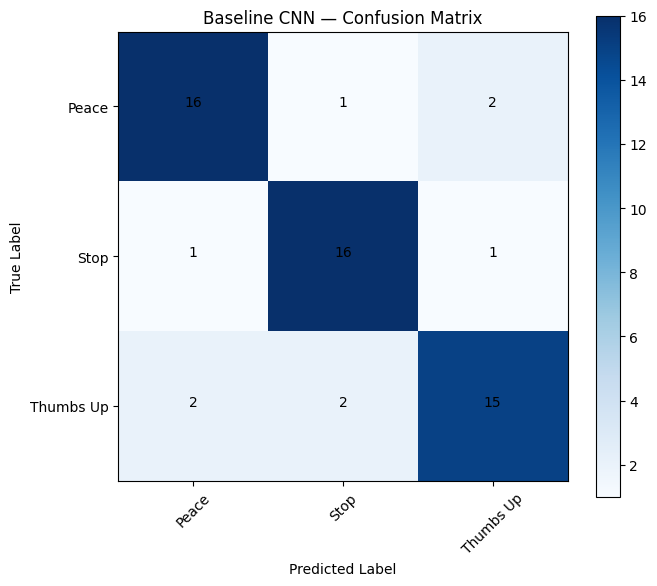

In [124]:
cm_baseline = confusion_matrix(
    y_true,
    y_pred_baseline
)

plt.figure(figsize=(7, 6))

plt.imshow(
    cm_baseline,
    cmap="Blues"
)

plt.title("Baseline CNN — Confusion Matrix")
plt.colorbar()

tick_marks = np.arange(
    len(class_names)
)

plt.xticks(
    tick_marks,
    [name.replace("_", " ").title() for name in class_names],
    rotation=45
)

plt.yticks(
    tick_marks,
    [name.replace("_", " ").title() for name in class_names]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(
    cm_baseline.shape[0]
):
    for j in range(
        cm_baseline.shape[1]
    ):
        plt.text(
            j,
            i,
            cm_baseline[i, j],
            horizontalalignment="center"
        )

plt.tight_layout()
plt.show()

### 9.3 Example Predictions

Several test images are displayed together with their true and predicted labels to visually inspect the baseline model's classification performance.

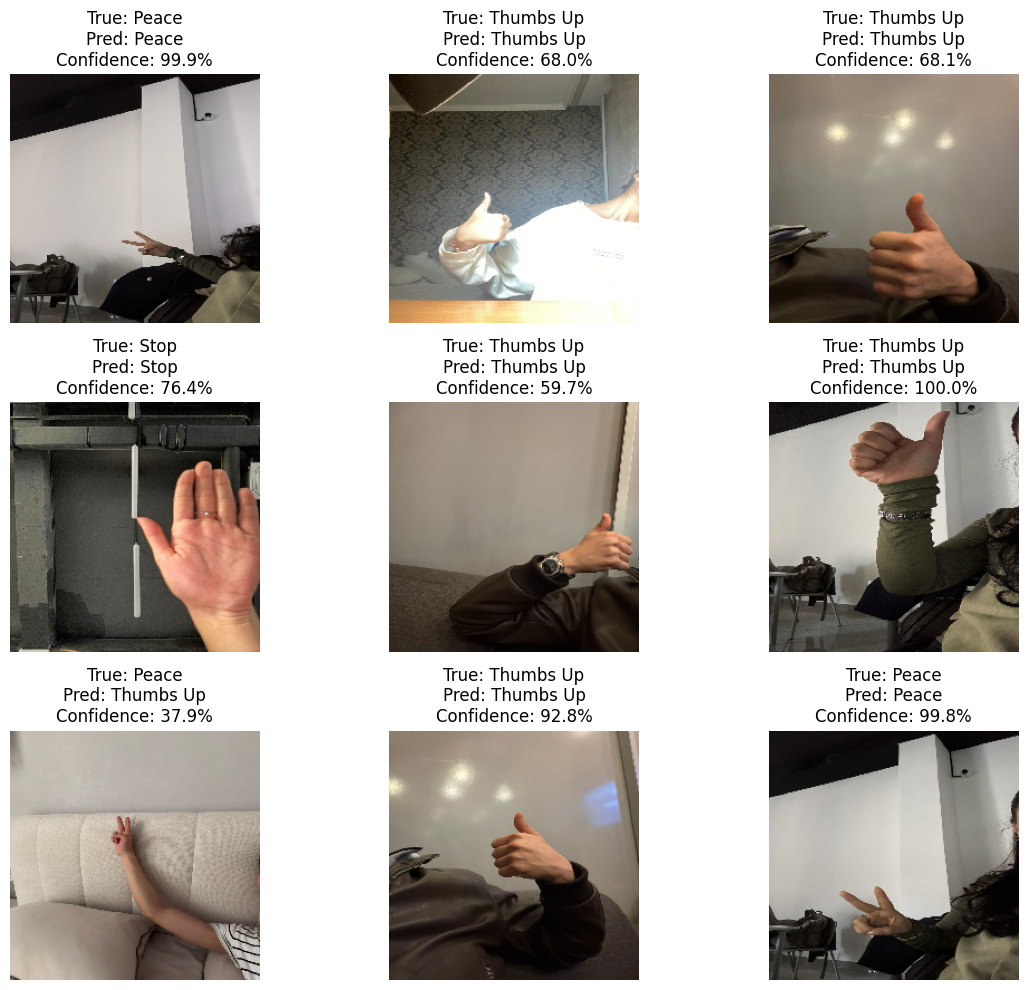

In [125]:
plt.figure(figsize=(12, 10))

displayed = 0

for images, labels_batch in test_ds:

    predictions = baseline_model.predict(
        images,
        verbose=0
    )

    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    for i in range(len(images)):

        if displayed >= 9:
            break

        plt.subplot(3, 3, displayed + 1)

        plt.imshow(
            tf.cast(images[i], tf.uint8)
        )

        true_name = class_names[
            labels_batch[i].numpy()
        ].replace("_", " ").title()

        predicted_name = class_names[
            predicted_classes[i]
        ].replace("_", " ").title()

        confidence = np.max(
            predictions[i]
        ) * 100

        plt.title(
            f"True: {true_name}\n"
            f"Pred: {predicted_name}\n"
            f"Confidence: {confidence:.1f}%"
        )

        plt.axis("off")

        displayed += 1

    if displayed >= 9:
        break

plt.tight_layout()
plt.show()

## 10. Improved Model — Transfer Learning with MobileNetV2

To improve classification performance, transfer learning is applied using **MobileNetV2**, a convolutional neural network pretrained on the ImageNet dataset.

Instead of learning all visual features from scratch, the pretrained model provides previously learned feature representations such as edges, textures, shapes, and more complex visual patterns.

The pretrained convolutional base is initially frozen, while a new classification head is trained for the three hand gesture classes.

Transfer learning uses knowledge learned by a model on a large existing dataset and adapts it to a new task.

In [126]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("MobileNetV2 loaded successfully.")
print("Base model trainable:", base_model.trainable)

MobileNetV2 loaded successfully.
Base model trainable: False


I froze the pretrained MobileNetV2 layers to preserve the features already learned from ImageNet.

### 10.1 Transfer Learning Architecture

The improved model combines the same data augmentation pipeline with the pretrained MobileNetV2 feature extractor.

Global Average Pooling is used to convert the extracted feature maps into a compact feature vector. Dropout is included to reduce overfitting, and the final Softmax layer performs three-class classification.

In [127]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

inputs = tf.keras.Input(
    shape=(224, 224, 3)
)

x = data_augmentation(
    inputs
)

x = preprocess_input(
    x
)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

transfer_model = tf.keras.Model(
    inputs,
    outputs
)

transfer_model.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 10.2 Model Compilation

The transfer learning model is compiled using the Adam optimizer with a lower learning rate than the baseline CNN.

A smaller learning rate allows the new classification layers to learn gradually while using the pretrained MobileNetV2 features.

In [128]:
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Transfer learning model compiled successfully.")

Transfer learning model compiled successfully.


In [129]:
transfer_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

print("Early stopping configured for MobileNetV2.")

Early stopping configured for MobileNetV2.


### 10.3 Transfer Learning Model Training

The MobileNetV2 convolutional base remains frozen during the initial training stage. Only the newly added classification layers are trained on the hand gesture dataset.

In [130]:
TRANSFER_EPOCHS = 20

history_transfer = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=TRANSFER_EPOCHS,
    callbacks=[transfer_early_stopping]
)

Epoch 1/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - accuracy: 0.3731 - loss: 1.5425 - val_accuracy: 0.2857 - val_loss: 1.2678
Epoch 2/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.3154 - loss: 1.3960 - val_accuracy: 0.4107 - val_loss: 1.2331
Epoch 3/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.3538 - loss: 1.3478 - val_accuracy: 0.4286 - val_loss: 1.2071
Epoch 4/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.3654 - loss: 1.2466 - val_accuracy: 0.4107 - val_loss: 1.1818
Epoch 5/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.3423 - loss: 1.3091 - val_accuracy: 0.4464 - val_loss: 1.1493
Epoch 6/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.3577 - loss: 1.2381 - val_accuracy: 0.4464 - val_loss: 1.1217
Epoch 7/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.4231 - loss: 1.1897 - val_accuracy: 0.4464 - val_loss: 1.0965
Epoch 8/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.3731 - loss: 1.2233 - val_accuracy: 0.4107 - val_loss:

### 10.4 Training History

Training and validation curves are examined to evaluate the learning behavior and generalization ability of the transfer learning model.

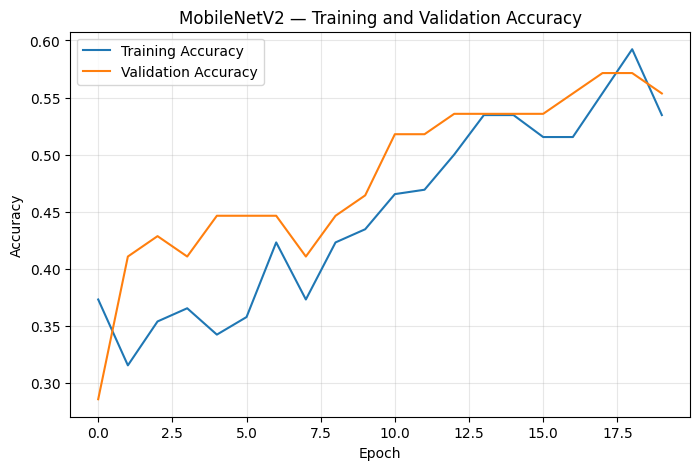

In [131]:
transfer_history_df = pd.DataFrame(
    history_transfer.history
)

plt.figure(figsize=(8, 5))

plt.plot(
    transfer_history_df["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    transfer_history_df["val_accuracy"],
    label="Validation Accuracy"
)

plt.title(
    "MobileNetV2 — Training and Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

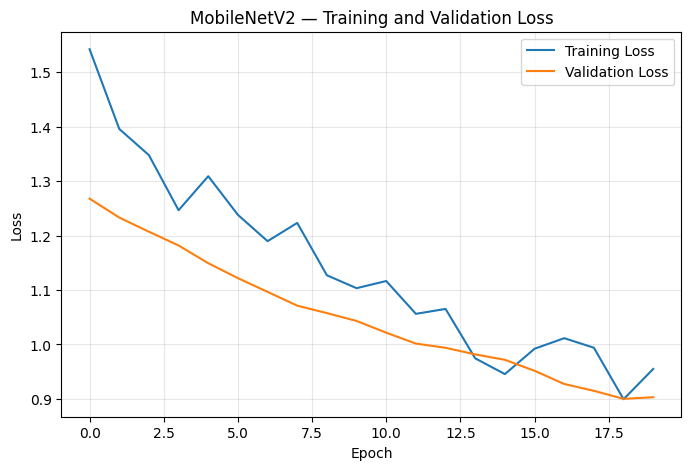

In [132]:
plt.figure(figsize=(8, 5))

plt.plot(
    transfer_history_df["loss"],
    label="Training Loss"
)

plt.plot(
    transfer_history_df["val_loss"],
    label="Validation Loss"
)

plt.title(
    "MobileNetV2 — Training and Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 11. Transfer Learning Model Evaluation

The trained MobileNetV2 model is evaluated on the same independent test dataset used to evaluate the baseline CNN. This enables a fair comparison between the two approaches.

In [133]:
transfer_test_loss, transfer_test_accuracy = transfer_model.evaluate(
    test_ds
)

print(
    f"MobileNetV2 Test Loss: "
    f"{transfer_test_loss:.4f}"
)

print(
    f"MobileNetV2 Test Accuracy: "
    f"{transfer_test_accuracy:.4f}"
)

4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 551ms/step - accuracy: 0.4821 - loss: 0.8782
MobileNetV2 Test Loss: 0.8782
MobileNetV2 Test Accuracy: 0.4821


In [134]:
y_pred_transfer = []

for images, labels_batch in test_ds:

    predictions = transfer_model.predict(
        images,
        verbose=0
    )

    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    y_pred_transfer.extend(
        predicted_classes
    )

y_pred_transfer = np.array(
    y_pred_transfer
)

print(
    "Predictions generated:",
    len(y_pred_transfer)
)

Predictions generated: 56


### 11.1 Classification Metrics

The transfer learning model is evaluated using the same metrics as the baseline CNN: accuracy, macro precision, macro recall, and macro F1-score.

In [135]:
transfer_accuracy = accuracy_score(
    y_true,
    y_pred_transfer
)

transfer_precision = precision_score(
    y_true,
    y_pred_transfer,
    average="macro",
    zero_division=0
)

transfer_recall = recall_score(
    y_true,
    y_pred_transfer,
    average="macro",
    zero_division=0
)

transfer_f1 = f1_score(
    y_true,
    y_pred_transfer,
    average="macro",
    zero_division=0
)

print(f"Accuracy:  {transfer_accuracy:.4f}")
print(f"Precision: {transfer_precision:.4f}")
print(f"Recall:    {transfer_recall:.4f}")
print(f"F1-score:  {transfer_f1:.4f}")

Accuracy:  0.4821
Precision: 0.4583
Recall:    0.4883
F1-score:  0.4517


In [136]:
print(
    classification_report(
        y_true,
        y_pred_transfer,
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       peace       0.38      0.16      0.22        19
        stop       0.62      0.83      0.71        18
   thumbs_up       0.38      0.47      0.42        19

    accuracy                           0.48        56
   macro avg       0.46      0.49      0.45        56
weighted avg       0.46      0.48      0.45        56



### 11.2 Confusion Matrix

The confusion matrix shows the class-level performance of the transfer learning model and helps identify which hand gestures are most frequently confused.

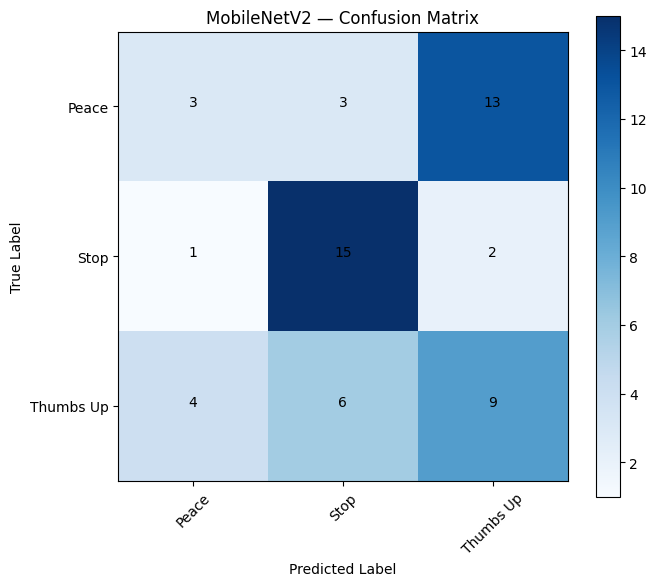

In [137]:
cm_transfer = confusion_matrix(
    y_true,
    y_pred_transfer
)

plt.figure(figsize=(7, 6))

plt.imshow(
    cm_transfer,
    cmap="Blues"
)

plt.title(
    "MobileNetV2 — Confusion Matrix"
)

plt.colorbar()

tick_marks = np.arange(
    len(class_names)
)

display_names = [
    name.replace("_", " ").title()
    for name in class_names
]

plt.xticks(
    tick_marks,
    display_names,
    rotation=45
)

plt.yticks(
    tick_marks,
    display_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(
    cm_transfer.shape[0]
):
    for j in range(
        cm_transfer.shape[1]
    ):
        plt.text(
            j,
            i,
            cm_transfer[i, j],
            horizontalalignment="center"
        )

plt.tight_layout()
plt.show()

### 11.3 Example Predictions

Example predictions from the test dataset are visualized together with the true class, predicted class, and model confidence.

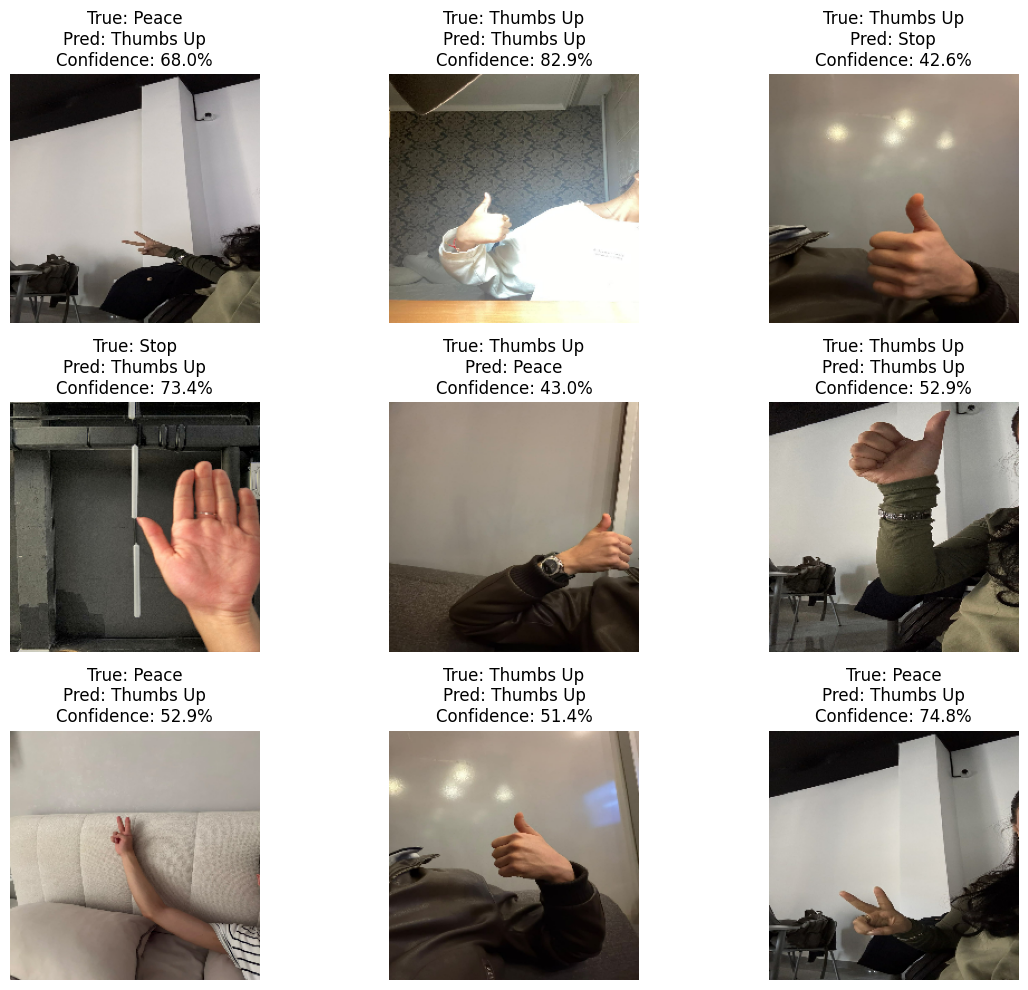

In [138]:
plt.figure(figsize=(12, 10))

displayed = 0

for images, labels_batch in test_ds:

    predictions = transfer_model.predict(
        images,
        verbose=0
    )

    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    for i in range(len(images)):

        if displayed >= 9:
            break

        plt.subplot(
            3,
            3,
            displayed + 1
        )

        plt.imshow(
            tf.cast(
                images[i],
                tf.uint8
            )
        )

        true_name = class_names[
            labels_batch[i].numpy()
        ].replace("_", " ").title()

        predicted_name = class_names[
            predicted_classes[i]
        ].replace("_", " ").title()

        confidence = (
            np.max(predictions[i]) * 100
        )

        plt.title(
            f"True: {true_name}\n"
            f"Pred: {predicted_name}\n"
            f"Confidence: {confidence:.1f}%"
        )

        plt.axis("off")

        displayed += 1

    if displayed >= 9:
        break

plt.tight_layout()
plt.show()

## 12. Fine-Tuning MobileNetV2

The initial transfer learning model used a completely frozen MobileNetV2 feature extractor. Its performance was lower than the baseline CNN.

To better adapt the pretrained features to the hand gesture dataset, fine-tuning is performed.

Most pretrained layers remain frozen, while only the final layers of MobileNetV2 are made trainable. A very small learning rate is used to avoid destroying the useful pretrained features.

In [139]:
base_model.trainable = True

# Freeze most of MobileNetV2
for layer in base_model.layers[:-30]:
    layer.trainable = False

print("Total MobileNetV2 layers:", len(base_model.layers))
print(
    "Trainable MobileNetV2 layers:",
    sum(layer.trainable for layer in base_model.layers)
)

Total MobileNetV2 layers: 154
Trainable MobileNetV2 layers: 30


### 12.1 Fine-Tuning Configuration

After unfreezing the final layers, the model is compiled again using a very small learning rate. This allows gradual adaptation of the pretrained features to the hand gesture images.

In [140]:
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning model compiled successfully.")

Fine-tuning model compiled successfully.


In [141]:
fine_tune_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [142]:
FINE_TUNE_EPOCHS = 15

history_fine = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=[fine_tune_early_stopping]
)

Epoch 1/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 46s 2s/step - accuracy: 0.5346 - loss: 0.9966 - val_accuracy: 0.5893 - val_loss: 0.8714
Epoch 2/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.5962 - loss: 0.8785 - val_accuracy: 0.5893 - val_loss: 0.8476
Epoch 3/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - accuracy: 0.6731 - loss: 0.7859 - val_accuracy: 0.5893 - val_loss: 0.8163
Epoch 4/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - accuracy: 0.6846 - loss: 0.7811 - val_accuracy: 0.5893 - val_loss: 0.7769
Epoch 5/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.6962 - loss: 0.7234 - val_accuracy: 0.5893 - val_loss: 0.7510
Epoch 6/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 40s 2s/step - accuracy: 0.7115 - loss: 0.6541 - val_accuracy: 0.6071 - val_loss: 0.7163
Epoch 7/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - accuracy: 0.7385 - loss: 0.6129 - val_accuracy: 0.6250 - val_loss: 0.6735
Epoch 8/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.7885 - loss: 0.5672 - val_accuracy: 0.6429 - val_loss:

### 12.2 Fine-Tuned Model Evaluation

After fine-tuning, the adapted MobileNetV2 model is evaluated again on the unchanged independent test dataset.

In [143]:
fine_test_loss, fine_test_accuracy = transfer_model.evaluate(
    test_ds
)

print(f"Fine-Tuned Test Loss: {fine_test_loss:.4f}")
print(f"Fine-Tuned Test Accuracy: {fine_test_accuracy:.4f}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 598ms/step - accuracy: 0.8036 - loss: 0.4782
Fine-Tuned Test Loss: 0.4782
Fine-Tuned Test Accuracy: 0.8036


In [144]:
y_pred_fine = []

for images, labels_batch in test_ds:

    predictions = transfer_model.predict(
        images,
        verbose=0
    )

    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    y_pred_fine.extend(predicted_classes)

y_pred_fine = np.array(y_pred_fine)

print("Fine-tuned predictions:", len(y_pred_fine))

Fine-tuned predictions: 56


In [145]:
fine_accuracy = accuracy_score(
    y_true,
    y_pred_fine
)

fine_precision = precision_score(
    y_true,
    y_pred_fine,
    average="macro",
    zero_division=0
)

fine_recall = recall_score(
    y_true,
    y_pred_fine,
    average="macro",
    zero_division=0
)

fine_f1 = f1_score(
    y_true,
    y_pred_fine,
    average="macro",
    zero_division=0
)

print(f"Accuracy:  {fine_accuracy:.4f}")
print(f"Precision: {fine_precision:.4f}")
print(f"Recall:    {fine_recall:.4f}")
print(f"F1-score:  {fine_f1:.4f}")

Accuracy:  0.8036
Precision: 0.8297
Recall:    0.8070
F1-score:  0.7956


### 12.3 Fine-Tuned MobileNetV2 Confusion Matrix

The confusion matrix is used to examine the class-level performance of the fine-tuned MobileNetV2 model and identify the remaining classification errors.

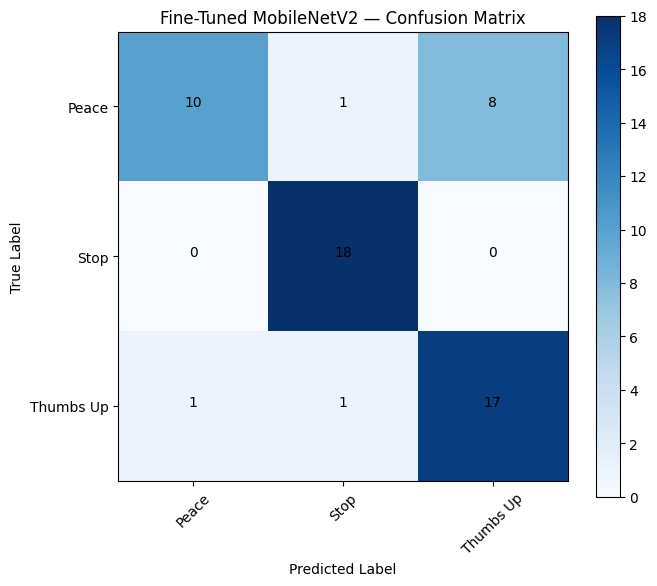

In [146]:
cm_fine = confusion_matrix(
    y_true,
    y_pred_fine
)

plt.figure(figsize=(7, 6))

plt.imshow(
    cm_fine,
    cmap="Blues"
)

plt.title(
    "Fine-Tuned MobileNetV2 — Confusion Matrix"
)

plt.colorbar()

tick_marks = np.arange(len(class_names))

display_names = [
    name.replace("_", " ").title()
    for name in class_names
]

plt.xticks(
    tick_marks,
    display_names,
    rotation=45
)

plt.yticks(
    tick_marks,
    display_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(cm_fine.shape[0]):
    for j in range(cm_fine.shape[1]):
        plt.text(
            j,
            i,
            cm_fine[i, j],
            horizontalalignment="center"
        )

plt.tight_layout()
plt.show()

## 13. Model Comparison

The baseline CNN and the fine-tuned MobileNetV2 are compared using the same independent test dataset.

The comparison is based on accuracy, macro precision, macro recall, and macro F1-score. Using the same test dataset provides a consistent evaluation of both approaches.

In [147]:
comparison_df = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "Fine-Tuned MobileNetV2"
    ],
    "Accuracy": [
        baseline_accuracy,
        fine_accuracy
    ],
    "Precision": [
        baseline_precision,
        fine_precision
    ],
    "Recall": [
        baseline_recall,
        fine_recall
    ],
    "F1-score": [
        baseline_f1,
        fine_f1
    ]
})

comparison_df

,Model,Accuracy,Precision,Recall,F1-score
0,Baseline CNN,0.839286,0.839181,0.840156,0.839260
1,Fine-Tuned MobileNetV2,0.803571,0.829697,0.807018,0.795587


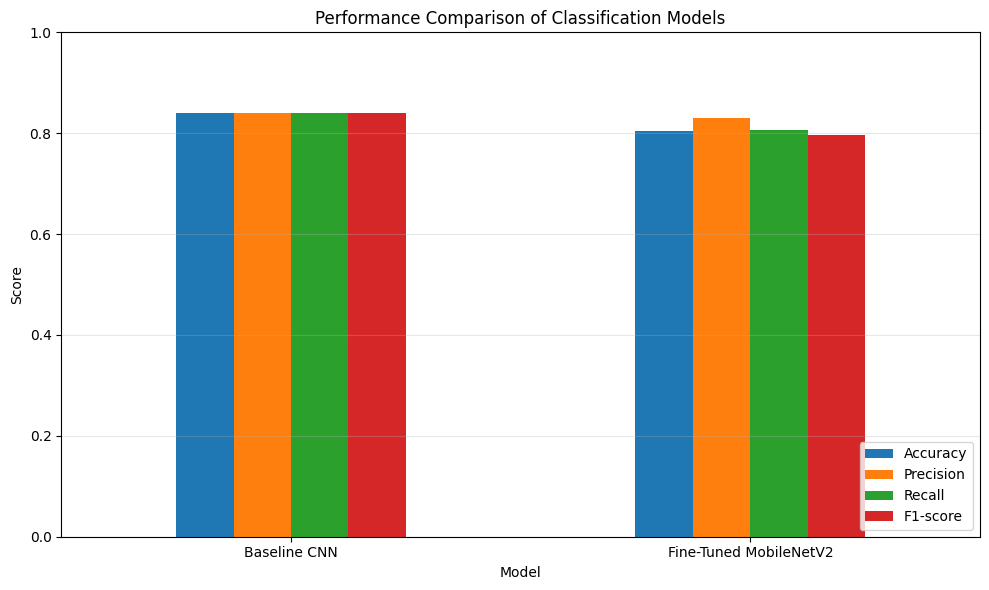

In [148]:
comparison_plot = comparison_df.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Performance Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")

plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [149]:
accuracy_difference = (
    baseline_accuracy - fine_accuracy
) * 100

f1_difference = (
    baseline_f1 - fine_f1
) * 100

print(
    f"Baseline CNN accuracy advantage: "
    f"{accuracy_difference:.2f} percentage points"
)

print(
    f"Baseline CNN F1-score advantage: "
    f"{f1_difference:.2f} percentage points"
)

Baseline CNN accuracy advantage: 3.57 percentage points
Baseline CNN F1-score advantage: 4.37 percentage points


## 14. Discussion

The experiments show that both the baseline CNN and transfer learning can be used for hand gesture recognition.

The baseline CNN achieved the best overall performance, with **83.93% accuracy**, **83.92% macro precision**, **84.02% macro recall**, and **83.93% macro F1-score** on the test dataset.

The initial MobileNetV2 model with a completely frozen convolutional base achieved lower performance, with an accuracy of **48.21%**. This indicates that the pretrained ImageNet features alone were not sufficiently adapted to the characteristics of the self-collected hand gesture dataset.

Fine-tuning the final layers of MobileNetV2 substantially improved its performance. The fine-tuned model achieved **80.36% accuracy**, **82.97% macro precision**, **80.70% macro recall**, and **79.56% macro F1-score**.

Although fine-tuning greatly improved MobileNetV2, the baseline CNN still achieved the highest overall performance. Its test accuracy was approximately **3.57 percentage points higher** than that of the fine-tuned MobileNetV2.

One possible explanation is that the dataset is relatively small and contains only three gesture classes. A simple CNN trained directly on these images may adapt effectively to the specific characteristics of the dataset without requiring a large pretrained architecture.

The experiment also demonstrates that a more complex pretrained model does not automatically guarantee better performance. Model performance depends on the dataset, training strategy, and degree of adaptation.

The remaining classification errors may be related to similarities between some hand shapes, differences in hand orientation, lighting conditions, backgrounds, and the relatively small size of the dataset.

Future improvements could include collecting more images from different people, using more diverse backgrounds and lighting conditions, adding additional gesture classes, and testing the system for real-time gesture recognition.

## 15. Conclusion

This project developed a computer vision system for recognizing three hand gestures: **Peace, Stop, and Thumbs Up**.

A self-collected dataset containing **372 original images** was prepared. The images were resized to **224 × 224 pixels** and divided into training, validation, and test sets. Data augmentation was applied to the training data to increase image diversity.

Two main approaches were investigated: a baseline Convolutional Neural Network (CNN) and transfer learning using MobileNetV2.

The baseline CNN achieved the best overall test performance, with **83.93% accuracy** and a macro F1-score of **83.93%**.

The initially frozen MobileNetV2 achieved **48.21% accuracy**. After fine-tuning its final layers, its performance improved substantially to **80.36% accuracy** and a macro F1-score of **79.56%**.

The results demonstrate that fine-tuning was important for adapting MobileNetV2 to the hand gesture dataset. However, for this particular dataset, the simpler baseline CNN achieved the highest overall classification performance.

Future work could include increasing the size and diversity of the dataset, collecting images from more people and environments, adding additional gesture classes, and implementing real-time hand gesture recognition using a camera.

## 16. Save the Best Model

Based on the final test results, the baseline CNN achieved the highest overall performance. Therefore, it is selected and saved as the final model for this project.

In [150]:
MODEL_PATH = (
    "/content/drive/MyDrive/"
    "Computer_Vision_Assignment/"
    "best_hand_gesture_cnn.keras"
)

baseline_model.save(MODEL_PATH)

print("Best model saved successfully.")
print("Location:", MODEL_PATH)

Best model saved successfully.
Location: /content/drive/MyDrive/Computer_Vision_Assignment/best_hand_gesture_cnn.keras


## 17. Final Project Summary

**Task:** Multi-class hand gesture image classification

**Classes:** Peace, Stop, Thumbs Up

**Original Dataset:** 372 self-collected images

**Image Size:** 224 × 224 pixels

**Dataset Split:** Approximately 70% training, 15% validation, and 15% testing

**Preprocessing:** Image resizing and normalization

**Data Augmentation:** Horizontal flipping, rotation, zoom, translation, and contrast adjustment

**Baseline Model:** Simple CNN

**Baseline Test Accuracy:** 83.93%

**Baseline Macro Precision:** 83.92%

**Baseline Macro Recall:** 84.02%

**Baseline Macro F1-score:** 83.93%

**Transfer Learning Model:** MobileNetV2

**Initial Frozen MobileNetV2 Accuracy:** 48.21%

**Fine-Tuned MobileNetV2 Accuracy:** 80.36%

**Fine-Tuned MobileNetV2 Macro Precision:** 82.97%

**Fine-Tuned MobileNetV2 Macro Recall:** 80.70%

**Fine-Tuned MobileNetV2 Macro F1-score:** 79.56%

The baseline CNN achieved the best overall performance on the independent test dataset. Fine-tuning substantially improved MobileNetV2 compared with its initially frozen configuration, but the simpler CNN remained the best-performing model for this dataset.